# EEG features vs behaviour (VTC, reaction time, accuracy)

How the single-trial EEG features from `extract_EEG_trial_features.py` relate to attention state and behaviour
in gradCPT. Run `extract_EEG_trial_features.py` first; it writes
`<data_save_path>/<subject>/features/<subject>_EEG_trial_features.csv.gz`.

**Behavioural variables** (per trial, within run)

| Variable | Definition | Used with |
|---|---|---|
| `VTC_smoothed` | smoothed variance time course (high = out of the zone) | all features |
| `VTC` | unsmoothed VTC (interpolated on trials without a press, e.g. mnt-correct) | all features |
| `RT` | own-trial reaction time; only `city_correct` trials have one (mnt-correct = withhold, RT = 0) | band power |
| `RT_prev` | mean RT of the `RT_PREV_N` preceding `city_correct` trials (local response speed) | all features |
| accuracy | mnt-correct vs mnt-incorrect, Cohen's d (correct minus incorrect) | all features |

**Feature families**
* *Band power*: log10 absolute and relative power, 20 s before / after onset, all channels. VTC / `RT_prev`: all trials; `RT`: `city_correct`; accuracy: mountain trials.
* *ERP*: N2 / P3 estimators, `mnt_correct` trials clean on that channel; accuracy: clean mnt-correct vs clean mnt-incorrect.

**Statistics** (two-level summary statistics)
1. Per subject: Spearman r between feature and behaviour. *partial* = after regressing the ranks on run and time-on-task (trial index within run, per run), so slow drifts shared by both do not drive r. Band power (20 s windows) and `VTC_smoothed` are strongly autocorrelated, so per-subject p-values are not valid and are not used.
2. Group: Fisher-z mean across subjects, one-sample t-test against 0 (one value per subject, valid despite the autocorrelation); Benjamini-Hochberg FDR within each (family, behaviour, r type). Accuracy: t-test of per-subject d against 0.

Outputs go to `<data_save_path>/xSubj_results/EEG_features_vs_behavior/`.

## 1. Setup

In [1]:
%matplotlib inline
import os
import sys
import glob
import warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

code_dir = '/projectnb/nphfnirs/s/datasets/gradCPT_NN24/code/eeg/preproc_pipe'
sys.path.insert(0, code_dir)
from utils import data_save_path
from extract_EEG_trial_features import get_features_path, CH_NAMES, BANDS, COMPONENTS

warnings.filterwarnings('ignore', category=stats.ConstantInputWarning)

Using matplotlib as 2D backend.


In [2]:
EXCLUDE_FNIRS_BAD = False  # True: drop the low-fNIRS-quality subjects in ../modeling/params_setting.excluded_subj

OUT_DIR = os.path.join(data_save_path, 'xSubj_results', 'EEG_features_vs_behavior')
RT_PREV_N = 3            # preceding city_correct trials averaged for RT_prev
MIN_TRIALS = 30          # trials per subject for a correlation
MIN_ACC_TRIALS = 5       # clean trials per condition for the accuracy contrast
MIN_SUBJ = 6             # subjects needed for a group test
FDR_Q = 0.05
N_TOP = 8                # features shown in the subject-level and binned figures
N_BINS = 5               # VTC quantile bins (within subject)

ERP_MEASURES = ['meanamp', 'area', 'area_signed', 'lat_fal50', 'amp_localpeak', 'lat_localpeak',
                'amp_woody', 'lat_woody', 'amp_mlr', 'lat_mlr']
BEHAV_CORR = {'band': ['VTC_smoothed', 'VTC', 'RT', 'RT_prev'],
              'erp': ['VTC_smoothed', 'VTC', 'RT_prev']}

# palette: reference dataviz palette (blue <-> gray <-> red diverging; categorical slots in fixed order)
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e6e5e0'
DIVERGING = LinearSegmentedColormap.from_list('div', ['#184f95', '#2a78d6', '#f0efec', '#e34948', '#a8302f'])
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#999999',
                     'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'font.size': 9,
                     'axes.titlesize': 10, 'axes.titlecolor': INK, 'figure.facecolor': '#fcfcfb',
                     'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb'})

## 2. Feature lists and data loading

In [3]:
def band_features():
    out = []
    for ch in CH_NAMES:
        for side in ['pre', 'post']:
            for b in BANDS:
                out += [f'{ch}_{b}_{side}_log', f'{ch}_{b}_{side}_rel']
    return out


def erp_features():
    return [f'{ch}_{c}_{m}' for ch in CH_NAMES for c in COMPONENTS for m in ERP_MEASURES]


def load_all(exclude=()):
    dfs = []
    for p in sorted(glob.glob(get_features_path('sub-*'))):
        subj = os.path.basename(os.path.dirname(os.path.dirname(p)))
        if subj in exclude:
            continue
        dfs.append(add_behaviour(pd.read_csv(p)))
    df = pd.concat(dfs, ignore_index=True)
    logs = {f: np.log10(df[f[:-4]]) for f in band_features() if f.endswith('_log')}
    return pd.concat([df, pd.DataFrame(logs)], axis=1)


def add_behaviour(df):
    df = df.sort_values(['run', 'trial_idx']).reset_index(drop=True)
    df['RT'] = np.where((df.trial_type == 'city') & (df.response_code == 1), df.reaction_time, np.nan)
    rt_prev = []
    for _, g in df.groupby('run', sort=False):
        # mean RT of the last RT_PREV_N city_correct trials strictly before each trial
        rt_prev.append(g['RT'].shift(1).rolling(len(g), min_periods=1)
                       .apply(lambda x: np.nanmean(x[~np.isnan(x)][-RT_PREV_N:])
                              if (~np.isnan(x)).sum() >= RT_PREV_N else np.nan, raw=True))
    df['RT_prev'] = pd.concat(rt_prev).values
    df['condition'] = np.select([(df.trial_type == 'city') & (df.response_code == 1),
                                 (df.trial_type == 'city'),
                                 (df.trial_type == 'mnt') & (df.response_code == 0)],
                                ['city_correct', 'city_incorrect', 'mnt_correct'], 'mnt_incorrect')
    return df

In [4]:
exclude = ()
if EXCLUDE_FNIRS_BAD:
    sys.path.insert(0, os.path.join(code_dir, os.pardir, 'modeling'))
    from params_setting import excluded_subj
    exclude = tuple(excluded_subj)
os.makedirs(OUT_DIR, exist_ok=True)

df = load_all(exclude)
print(f"{df.subject.nunique()} subjects, {len(df):,} trials")

18 subjects, 23,690 trials


### 2.1 Behaviour: how VTC and RT relate
Per-subject Spearman r, and the number of mountain trials per condition.

In [5]:
beh = df.groupby('subject').apply(lambda g: pd.Series({
    'r(VTC_smoothed, RT_prev)': stats.spearmanr(g.VTC_smoothed, g.RT_prev, nan_policy='omit')[0],
    'r(VTC, RT) city_correct': stats.spearmanr(g.VTC[g.condition == 'city_correct'],
                                               g.RT[g.condition == 'city_correct'])[0],
    'mnt_correct': (g.condition == 'mnt_correct').sum(),
    'mnt_incorrect': (g.condition == 'mnt_incorrect').sum()}), include_groups=False)
beh.to_csv(os.path.join(OUT_DIR, 'behaviour_summary.csv'))
beh.round(3)

,"r(VTC_smoothed, RT_prev)","r(VTC, RT) city_correct",mnt_correct,mnt_incorrect
subject,,,,
sub-670,0.101,0.052,128.0,9.0
sub-671,0.066,0.030,98.0,33.0
sub-673,0.061,0.010,88.0,42.0
sub-695,0.140,0.046,95.0,33.0
sub-719,0.047,-0.028,102.0,29.0
sub-721,-0.028,-0.017,108.0,23.0
sub-723,0.087,0.015,124.0,5.0
sub-726,0.048,-0.006,83.0,47.0
sub-727,0.068,0.123,83.0,54.0


## 3. Statistics

In [6]:
def time_residual_ranks(x, run, tidx):
    """Ranks of x with run means and a per-run linear time-on-task trend removed."""
    r = stats.rankdata(x)
    out = np.empty_like(r, dtype=float)
    for u in np.unique(run):
        m = run == u
        A = np.column_stack([np.ones(m.sum()), tidx[m]])
        out[m] = r[m] - A @ np.linalg.lstsq(A, r[m], rcond=None)[0]
    return out


def spearman_pair(x, y, run, tidx):
    m = np.isfinite(x) & np.isfinite(y)
    if m.sum() < MIN_TRIALS or np.std(x[m]) == 0 or np.std(y[m]) == 0:
        return np.nan, np.nan, int(m.sum())
    r_raw = stats.spearmanr(x[m], y[m])[0]
    rx = time_residual_ranks(x[m], run[m], tidx[m])
    ry = time_residual_ranks(y[m], run[m], tidx[m])
    r_part = np.corrcoef(rx, ry)[0, 1]
    return r_raw, r_part, int(m.sum())


def cohens_d(a, b):
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    if len(a) < MIN_ACC_TRIALS or len(b) < MIN_ACC_TRIALS:
        return np.nan
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp if sp > 0 else np.nan


def trial_mask(g, family, behav, feat):
    """Trials used for one (family, behaviour, feature) test."""
    if family == 'band':
        return (g.condition == 'city_correct').values if behav == 'RT' else np.ones(len(g), bool)
    ch = feat.split('_')[0]
    return ((g.condition == 'mnt_correct') & (g[f'{ch}_erp_ok'] == True)).values


def per_subject_stats(df):
    rows = []
    fams = {'band': band_features(), 'erp': erp_features()}
    for subj, g in df.groupby('subject'):
        run, tidx = g.run.values, g.trial_idx.values.astype(float)
        for family, feats in fams.items():
            for feat in feats:
                if feat not in g or g[feat].notna().sum() == 0:
                    continue
                x_all = g[feat].values.astype(float)
                for behav in BEHAV_CORR[family]:
                    m = trial_mask(g, family, behav, feat)
                    r_raw, r_part, n = spearman_pair(x_all[m], g[behav].values[m].astype(float), run[m], tidx[m])
                    rows.append(dict(subject=subj, family=family, feature=feat, behaviour=behav,
                                     stat='r', raw=r_raw, partial=r_part, n=n))
                # accuracy: mountain trials, correct minus incorrect (clean epochs for ERP)
                if family == 'erp':
                    ok = (g[f"{feat.split('_')[0]}_erp_ok"] == True).values
                else:
                    ok = np.ones(len(g), bool)
                d = cohens_d(x_all[(g.condition == 'mnt_correct').values & ok],
                             x_all[(g.condition == 'mnt_incorrect').values & ok])
                rows.append(dict(subject=subj, family=family, feature=feat, behaviour='accuracy',
                                 stat='d', raw=d, partial=np.nan,
                                 n=int(((g.condition.str.startswith('mnt')).values & ok).sum())))
    return pd.DataFrame(rows)


def bh_fdr(p):
    p = np.asarray(p, float)
    q = np.full_like(p, np.nan)
    m = np.isfinite(p)
    if m.sum() == 0:
        return q
    ps = p[m]
    order = np.argsort(ps)
    ranked = ps[order] * m.sum() / np.arange(1, m.sum() + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty_like(ps)
    out[order] = np.clip(ranked, 0, 1)
    q[m] = out
    return q


def group_stats(subj_df):
    rows = []
    for (family, feat, behav), g in subj_df.groupby(['family', 'feature', 'behaviour']):
        for rtype in (['raw'] if behav == 'accuracy' else ['raw', 'partial']):
            v = g[rtype].dropna().values
            row = dict(family=family, feature=feat, behaviour=behav, r_type=rtype, n_subj=len(v),
                       mean=np.nan, ci_lo=np.nan, ci_hi=np.nan, t=np.nan, p=np.nan)
            if len(v) >= MIN_SUBJ:
                z = v if behav == 'accuracy' else np.arctanh(np.clip(v, -0.999, 0.999))
                t, p = stats.ttest_1samp(z, 0)
                half = stats.t.ppf(0.975, len(z) - 1) * z.std(ddof=1) / np.sqrt(len(z))
                back = (lambda a: a) if behav == 'accuracy' else np.tanh
                row.update(mean=back(z.mean()), ci_lo=back(z.mean() - half), ci_hi=back(z.mean() + half),
                           t=t, p=p, n_pos=int((v > 0).sum()))
            rows.append(row)
    gdf = pd.DataFrame(rows)
    gdf['q'] = np.nan
    for _, idx in gdf.groupby(['family', 'behaviour', 'r_type']).groups.items():
        gdf.loc[idx, 'q'] = bh_fdr(gdf.loc[idx, 'p'])
    gdf['sig'] = gdf.q < FDR_Q
    return gdf

In [7]:
subj_df = per_subject_stats(df)
subj_df.to_csv(os.path.join(OUT_DIR, 'per_subject_stats.csv'), index=False)
gdf = group_stats(subj_df)
gdf.to_csv(os.path.join(OUT_DIR, 'group_stats.csv'), index=False)
print(f"{len(subj_df):,} per-subject values, {len(gdf):,} group tests")

11,328 per-subject values, 1,136 group tests


### 3.1 FDR-significant feature-behaviour pairs

In [8]:
sig = gdf[gdf.sig].sort_values('p')
print(f"{len(sig)} FDR-significant (q < {FDR_Q}) pairs")
sig[['family', 'feature', 'behaviour', 'r_type', 'n_subj', 'mean', 'ci_lo', 'ci_hi', 't', 'q']].round(3)

36 FDR-significant (q < 0.05) pairs


,family,feature,behaviour,r_type,n_subj,mean,ci_lo,ci_hi,t,q
1079,erp,pz_P3_amp_mlr,accuracy,raw,17,0.496,0.320,0.671,5.982,0.001
1086,erp,pz_P3_amp_woody,accuracy,raw,17,0.539,0.334,0.745,5.568,0.001
659,erp,cz_P3_amp_mlr,accuracy,raw,17,0.537,0.325,0.749,5.362,0.001
708,erp,cz_P3_lat_woody,accuracy,raw,17,-0.364,-0.511,-0.217,-5.259,0.001
946,erp,oz_P3_amp_woody,accuracy,raw,15,0.380,0.230,0.531,5.429,0.001
1072,erp,pz_P3_amp_localpeak,accuracy,raw,17,0.406,0.236,0.576,5.073,0.002
666,erp,cz_P3_amp_woody,accuracy,raw,17,0.610,0.341,0.879,4.810,0.002
1135,erp,pz_P3_meanamp,accuracy,raw,17,0.445,0.246,0.643,4.754,0.002
1100,erp,pz_P3_area_signed,accuracy,raw,17,0.446,0.247,0.644,4.753,0.002
458,band,pz_alpha_pre_log,accuracy,raw,17,-0.236,-0.342,-0.130,-4.712,0.015


### 3.2 Strongest non-significant ERP relations with VTC / RT_prev (time-on-task partialled)

In [9]:
e = gdf[(gdf.family == 'erp') & (gdf.behaviour != 'accuracy') & (gdf.r_type == 'partial')]
e.reindex(e.t.abs().sort_values(ascending=False).index).head(10)[
    ['feature', 'behaviour', 'n_subj', 'mean', 't', 'p', 'q']].round(3)

,feature,behaviour,n_subj,mean,t,p,q
626,cz_N2_lat_mlr,RT_prev,17,0.088,3.280,0.005,0.377
752,fz_N2_lat_fal50,RT_prev,17,0.065,2.764,0.014,0.553
1127,pz_P3_lat_woody,VTC_smoothed,17,0.055,2.434,0.027,0.692
612,cz_N2_lat_fal50,RT_prev,17,0.089,2.432,0.027,0.634
756,fz_N2_lat_fal50,VTC_smoothed,17,0.051,2.380,0.030,0.692
1106,pz_P3_lat_fal50,VTC_smoothed,17,0.075,2.269,0.037,0.692
700,cz_P3_lat_mlr,VTC_smoothed,17,0.055,2.188,0.044,0.692
665,cz_P3_amp_woody,VTC_smoothed,17,-0.049,-2.180,0.045,0.692
1046,pz_N2_lat_mlr,RT_prev,17,0.081,2.169,0.046,0.634
1120,pz_P3_lat_mlr,VTC_smoothed,17,0.055,2.100,0.052,0.692


## 4. Figures
Plot helpers (reference dataviz palette: blue-gray-red diverging for r / d).

In [10]:
def feature_label(feat):
    return feat.replace('_log', ' log').replace('_rel', ' rel').replace('_', ' ')


def heatmap(gdf, family, rtype, fname):
    behavs = BEHAV_CORR[family]
    sub = gdf[(gdf.family == family) & (gdf.r_type == rtype) & gdf.behaviour.isin(behavs)]
    acc = gdf[(gdf.family == family) & (gdf.behaviour == 'accuracy')]
    feats = [f for f in (band_features() if family == 'band' else erp_features()) if f in set(sub.feature)]
    if not feats:
        return
    M = sub.pivot(index='feature', columns='behaviour', values='mean').reindex(index=feats, columns=behavs)
    S = sub.pivot(index='feature', columns='behaviour', values='sig').reindex(index=feats, columns=behavs)
    A = acc.set_index('feature').reindex(feats)
    h = max(5, 0.17 * len(feats) + 1.5)
    fig, axes = plt.subplots(1, 2, figsize=(9.5, h), gridspec_kw=dict(width_ratios=[len(behavs), 1.2], wspace=0.08),
                             sharey=True)
    rmax = max(0.05, np.nanmax(np.abs(M.values)))
    dmax = max(0.1, np.nanmax(np.abs(A['mean'].values))) if A['mean'].notna().any() else 1
    for ax, vals, sig, cols, vmax, lab in [
            (axes[0], M.values, S.values.astype(float), behavs, rmax, 'group mean Spearman r'),
            (axes[1], A[['mean']].values, A[['sig']].values.astype(float), ['accuracy\n(d, C - IC)'], dmax,
             "group mean Cohen's d")]:
        im = ax.imshow(vals, cmap=DIVERGING, vmin=-vmax, vmax=vmax, aspect='auto', interpolation='nearest')
        ax.grid(False)
        ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=30, ha='right')
        for i in range(vals.shape[0]):
            for j in range(vals.shape[1]):
                if np.isfinite(vals[i, j]):
                    s = sig[i, j] == 1
                    ax.text(j, i, f"{vals[i, j]:.2f}{'*' if s else ''}", ha='center', va='center', fontsize=6.5,
                            color=INK, fontweight='bold' if s else 'normal')
        # separate channel blocks
        per_ch = len(feats) // len(CH_NAMES) if len(feats) % len(CH_NAMES) == 0 else None
        if per_ch:
            for k in range(1, len(CH_NAMES)):
                ax.axhline(k * per_ch - 0.5, color='#fcfcfb', lw=2)
        fig.colorbar(im, ax=ax, shrink=0.4, pad=0.02, label=lab)
    axes[0].set_yticks(range(len(feats))); axes[0].set_yticklabels([feature_label(f) for f in feats], fontsize=7)
    n_subj = int(sub.n_subj.max())
    rdesc = 'time-on-task partialled' if rtype == 'partial' else 'raw'
    fig.suptitle(f"{'Band power' if family == 'band' else 'ERP'} features vs behaviour ({rdesc} r; "
                 f"up to {n_subj} subjects)\n* / bold = FDR q < {FDR_Q} across features (one-sample t-test over subjects)",
                 x=0.02, ha='left', color=INK, fontsize=10)
    fig.savefig(os.path.join(OUT_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()


def top_features(gdf, n=N_TOP):
    g = gdf[(gdf.r_type == 'partial') | (gdf.behaviour == 'accuracy')].dropna(subset=['t'])
    return g.reindex(g.t.abs().sort_values(ascending=False).index).head(n)


def subject_dots(subj_df, top, fname):
    if top.empty:
        return
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(top) + 1.5))
    rng = np.random.default_rng(0)
    for i, (_, row) in enumerate(top.iterrows()):
        col = 'raw' if row.behaviour == 'accuracy' else 'partial'
        v = subj_df[(subj_df.feature == row.feature) & (subj_df.behaviour == row.behaviour)][col].dropna()
        y = len(top) - 1 - i
        ax.scatter(v, y + rng.uniform(-0.15, 0.15, len(v)), s=22, color=SERIES[0], alpha=0.55,
                   edgecolor='#fcfcfb', linewidth=1, zorder=3)
        ax.plot([row.ci_lo, row.ci_hi], [y, y], color=INK, lw=2, zorder=4)
        ax.plot(row['mean'], y, 'o', ms=8, color=INK, mec='#fcfcfb', mew=2, zorder=5)
    ax.axvline(0, color='#999999', lw=0.8)
    labels = [f"{feature_label(r.feature)}  vs  {r.behaviour}" + (" (d)" if r.behaviour == 'accuracy' else " (r)")
              + f"   q={r.q:.3f}" for _, r in top.iterrows()]
    ax.set_yticks(range(len(top))); ax.set_yticklabels(labels[::-1], fontsize=8)
    ax.grid(axis='y', visible=False)
    ax.set_xlabel("per-subject Spearman r (time-on-task partialled) or Cohen's d")
    ax.legend([Line2D([], [], ls='none', marker='o', color=SERIES[0], alpha=0.55, ms=5),
               Line2D([], [], color=INK, lw=2, marker='o', ms=6)],
              ['subject', 'group mean, 95% CI'], frameon=False, loc='lower right', fontsize=8)
    ax.set_title(f"Strongest {len(top)} feature-behaviour relations (largest |t| across subjects)", loc='left')
    fig.savefig(os.path.join(OUT_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()


def binned_by_vtc(df, gdf, fname):
    g = gdf[(gdf.r_type == 'partial') & (gdf.behaviour == 'VTC_smoothed')].dropna(subset=['t'])
    top = g.reindex(g.t.abs().sort_values(ascending=False).index).head(N_TOP)
    if top.empty:
        return
    ncol = 4
    nrow = int(np.ceil(len(top) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, 2.8 * nrow), squeeze=False)
    for ax, (_, row) in zip(axes.ravel(), top.iterrows()):
        curves = []
        for subj, s in df.groupby('subject'):
            m = trial_mask(s, row.family, 'VTC_smoothed', row.feature)
            x, v = s[row.feature].values[m].astype(float), s['VTC_smoothed'].values[m]
            ok = np.isfinite(x) & np.isfinite(v)
            if ok.sum() < MIN_TRIALS:
                continue
            x, v = x[ok], v[ok]
            z = (x - x.mean()) / x.std()
            bins = pd.qcut(stats.rankdata(v), N_BINS, labels=False)
            curves.append([z[bins == b].mean() for b in range(N_BINS)])
        C = np.array(curves)
        mu, se = C.mean(0), C.std(0, ddof=1) / np.sqrt(len(C))
        xb = np.arange(1, N_BINS + 1)
        ax.fill_between(xb, mu - se, mu + se, color=SERIES[0], alpha=0.2, lw=0)
        ax.plot(xb, mu, '-o', color=SERIES[0], lw=2, ms=8, mec='#fcfcfb', mew=2)
        ax.axhline(0, color='#999999', lw=0.8)
        ax.set_xticks(xb)
        ax.set_title(f"{feature_label(row.feature)}\nr={row['mean']:.2f}, q={row.q:.3f}, n={len(C)}",
                     loc='left', fontsize=8.5)
        ax.set_xlabel('VTC quintile (1 = in the zone)', fontsize=8)
        ax.set_ylabel('feature (z within subject)', fontsize=8)
    for ax in axes.ravel()[len(top):]:
        ax.set_visible(False)
    fig.suptitle('Feature by smoothed-VTC quintile (mean ± SEM across subjects), top features by |t|',
                 x=0.02, ha='left', color=INK)
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()

### 4.1 Band power heatmaps
Left: group mean r per behaviour; right: accuracy d. `*` / bold = FDR q < 0.05.

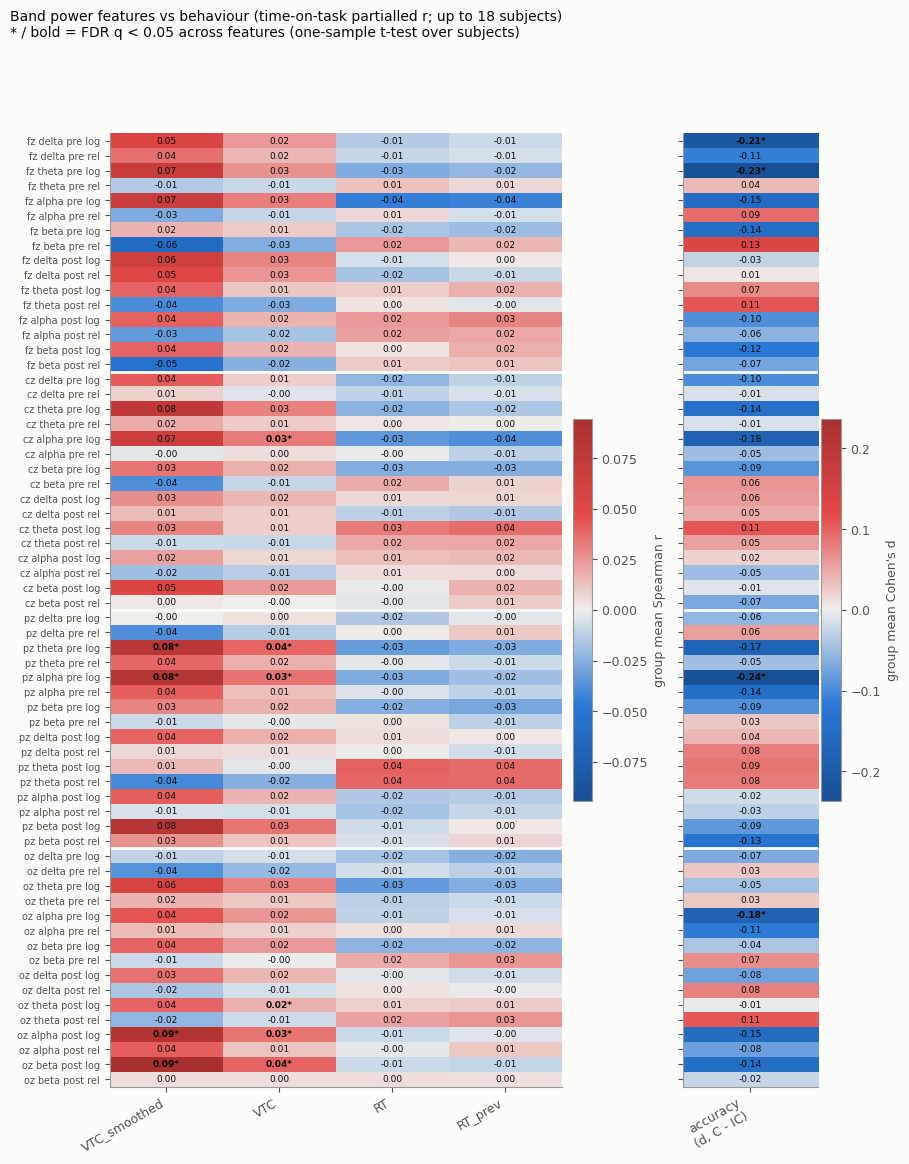

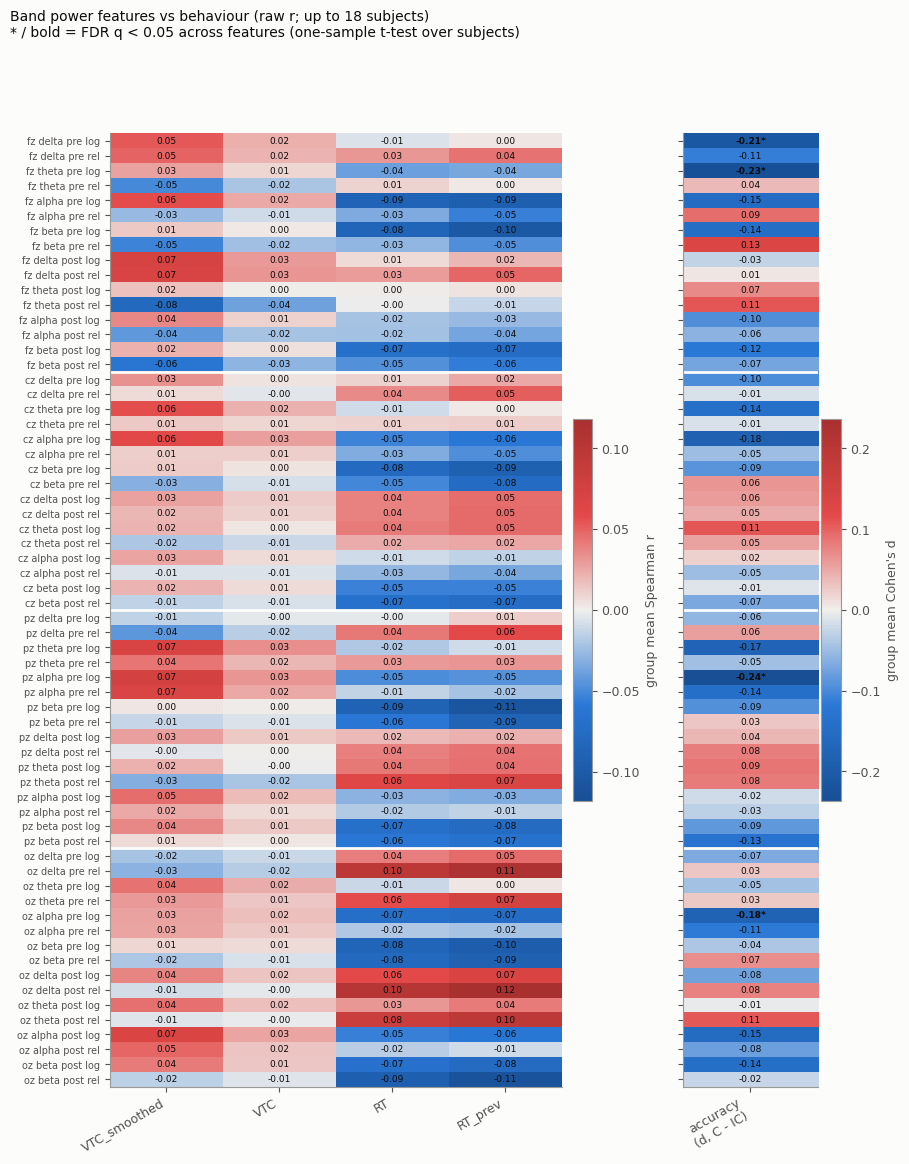

In [11]:
heatmap(gdf, 'band', 'partial', 'heatmap_band_partial.png')
heatmap(gdf, 'band', 'raw', 'heatmap_band_raw.png')

### 4.2 ERP heatmaps
Left: group mean r per behaviour; right: accuracy d. `*` / bold = FDR q < 0.05.

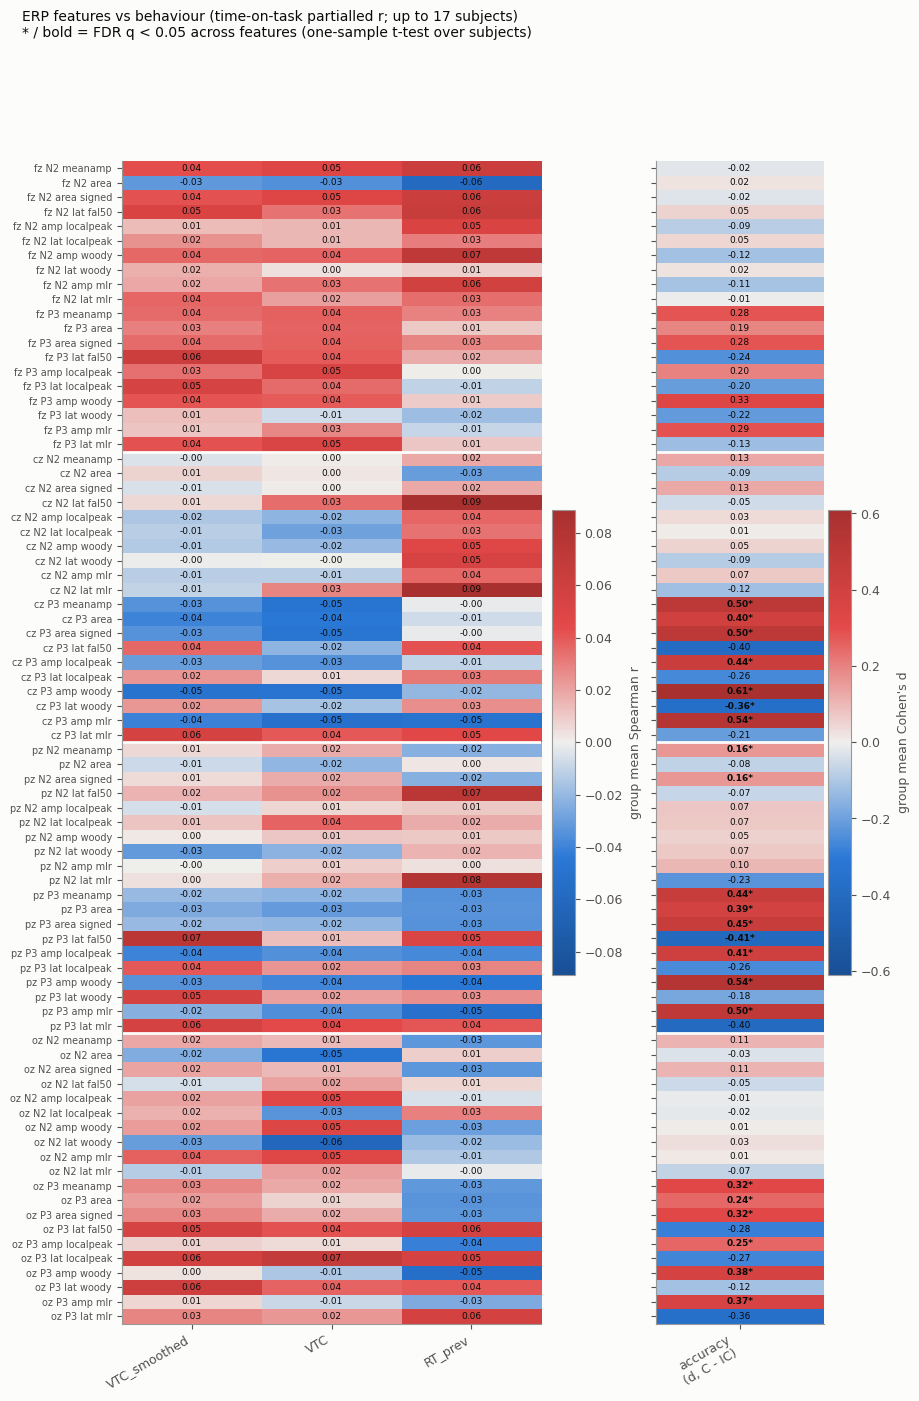

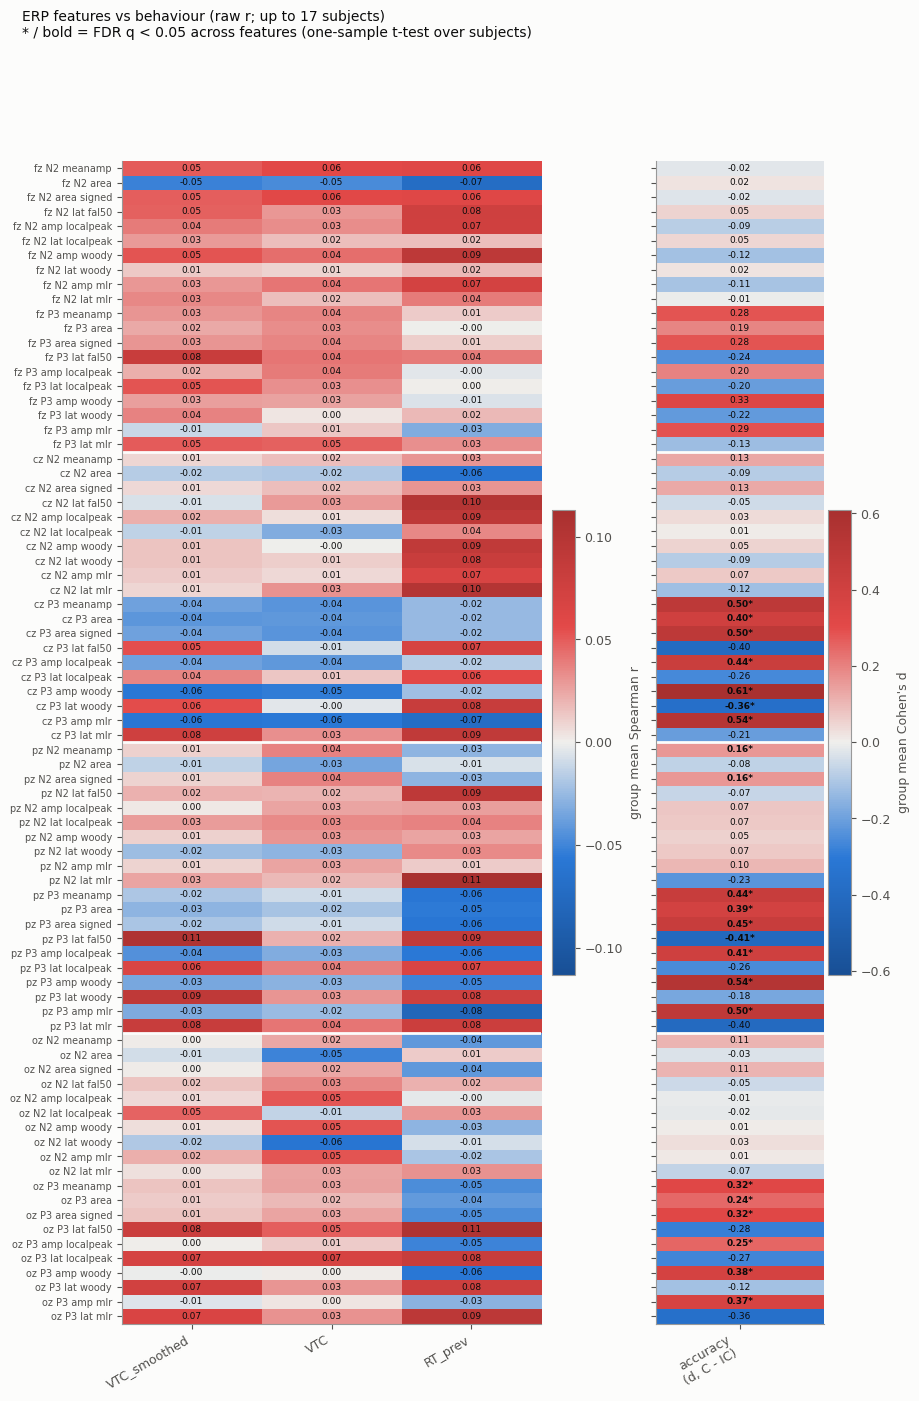

In [12]:
heatmap(gdf, 'erp', 'partial', 'heatmap_erp_partial.png')
heatmap(gdf, 'erp', 'raw', 'heatmap_erp_raw.png')

### 4.3 Subject-level values of the strongest relations

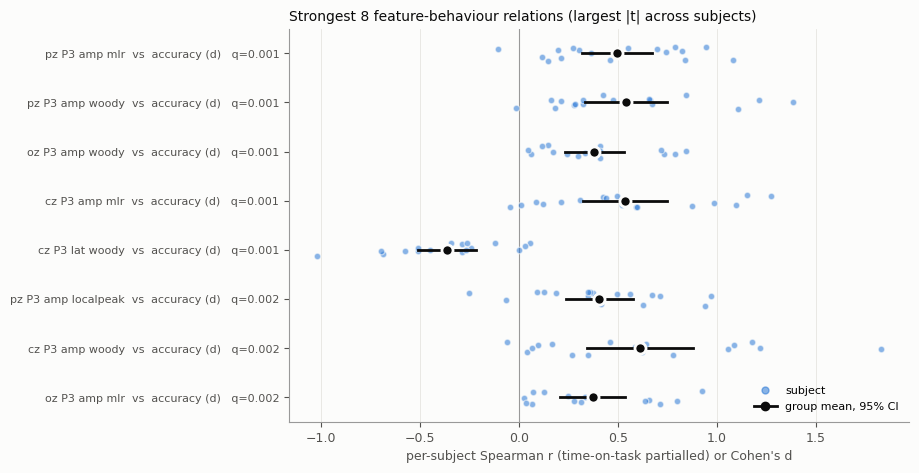

In [13]:
subject_dots(subj_df, top_features(gdf), 'subject_r_top_features.png')

### 4.4 Features by smoothed-VTC quintile
Curves use the feature z-scored within subject (not time-on-task partialled); the panel titles give the partialled r.

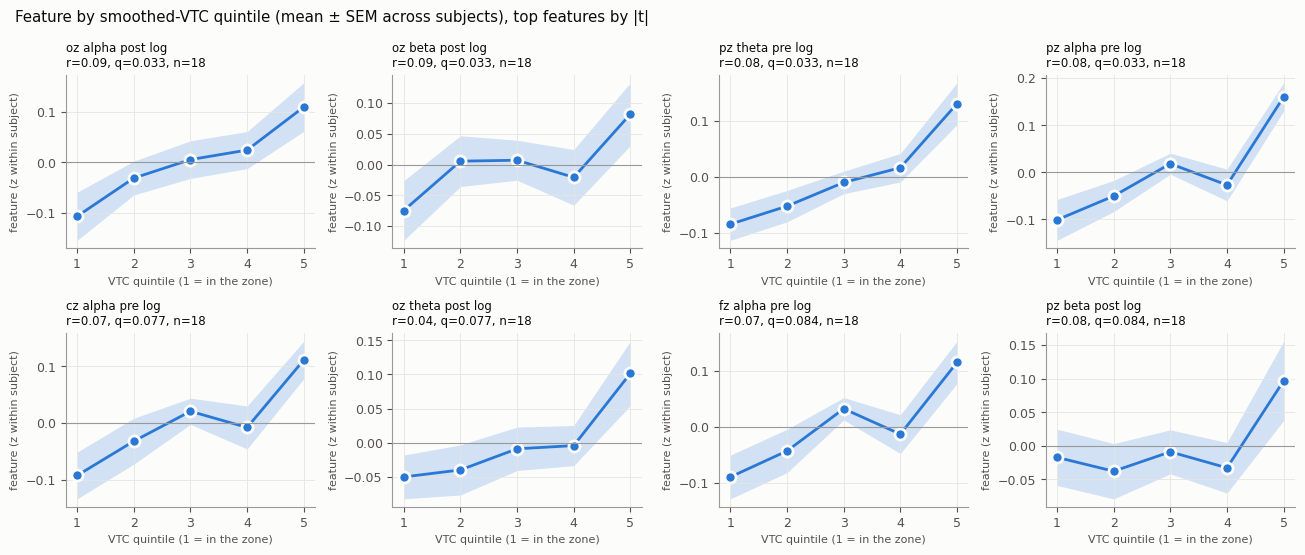

In [14]:
binned_by_vtc(df, gdf, 'binned_by_VTC_top_features.png')

## 5. Summary (run of 2026-11-05, 18 subjects)

* **P3 vs accuracy (strongest).** Correct withholds have a larger P3 than commission errors (d ≈ 0.4–0.6 at Cz/Pz, q ≤ 0.003, every amplitude estimator) and an earlier Cz woody latency (d = −0.36). **Caveat:** mnt-incorrect trials contain a button press (median RT 540 ms), so motor potentials overlap the P3 window; this contrast is partly confounded.
* **Pre-trial band power vs accuracy.** Errors follow higher Pz alpha (d = −0.24), Fz theta (−0.23) and Fz delta (−0.21) in the 20 s before onset.
* **Band power vs VTC_smoothed.** Out of the zone, theta/alpha/beta power at Pz/Oz is higher, consistently but weakly (time-on-task partialled r ≈ 0.08, q ≈ 0.03); the quintile curves rise monotonically.
* **ERP vs VTC / RT_prev:** nothing survives FDR (best: Cz N2 MLR latency vs RT_prev, r = 0.09, p = 0.005, q = 0.38).
* **Band power vs own-trial RT:** nothing survives FDR.
* **Behaviour:** VTC_smoothed and RT_prev barely correlate within subject (median r ≈ 0.05), so RT variability (VTC) and recent speed are largely separate dimensions.
* For the HRF design matrix: the VTC relations are reliable but tiny (r ≈ 0.08), so the EEG modulators carry little attention-state information beyond what VTC itself would.